# 03 · Fine-tuning NLLB-200 — E2, E3, E4, E5, E6

**Runtime:** GPU (**T4**). Every experiment is independent and logs to `results/experiments.csv` on Drive, so if Colab disconnects or you hit the GPU limit, reconnect, **re-run the setup cells (Sections 1–5)** and continue with the next experiment.

| ID | What changes | Research question |
|---|---|---|
| **E2** | Full fine-tune, swa→dav, 100% data | Does multilingual pretraining transfer to an unseen Bantu language? (compare with E1) |
| **E3** | Full fine-tune, dav→swa, 100% data | Is translating *into* the low-resource language harder? |
| **E6** | Full fine-tune, **both directions in one model** | Does sharing one model across directions help or hurt? → **this is the deployed model** |
| **E5** | Full fine-tune, swa→dav on **25% / 50%** of the data | How does quality grow with data? (100% point = E2) |
| **E4** | **LoRA** (parameter-efficient), swa→dav | Can training <1% of the parameters match full fine-tuning? |

Run them in this order: the first three are the core results and the deployment model; E5 and E4 come after.

**Rough T4 timings (the first epoch's printout shows the real speed):** ≈ 6–10 min per epoch on 15k pairs. E2/E3 ≈ 25–40 min each, E6 ≈ 45–60 min, E5 ≈ 30 min total, E4 ≈ 20–30 min.

**What is saved to Drive**
- Every run: test predictions (`results/predictions/`), validation curve (`results/curves/`), a row in `results/experiments.csv`.
- **Model weights only for E6** (final model, fp16 ≈ 1.2 GB → `models/nllb_dav_swa_final/`) and the E4 LoRA adapter (a few MB). E2/E3/E5 full checkpoints (2.4 GB each) are kept only on the Colab disk during training — saving them all would fill a free Drive.

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/kidawida-mt'
DATA_DIR    = f'{PROJECT_DIR}/data'
RESULTS_DIR = f'{PROJECT_DIR}/results'
PRED_DIR    = f'{RESULTS_DIR}/predictions'
CURVE_DIR   = f'{RESULTS_DIR}/curves'
MODELS_DIR  = f'{PROJECT_DIR}/models'
FIG_DIR     = f'{PROJECT_DIR}/figures'
LOCAL_CKPT  = '/content/ckpt'          # large temporary checkpoints: Colab disk, not Drive
for d in [RESULTS_DIR, PRED_DIR, CURVE_DIR, MODELS_DIR, FIG_DIR, LOCAL_CKPT]:
    os.makedirs(d, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q sacrebleu "peft>=0.13.2" "transformers>=4.45.0" --upgrade

import math, time, json, random, gc, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
import sacrebleu
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, get_constant_schedule_with_warmup
from transformers.optimization import Adafactor
from peft import LoraConfig, TaskType, get_peft_model

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = device == 'cuda'   # fp16 mixed precision (fp32 master weights). Set False if the loss becomes NaN.
print('device:', device, '|', torch.cuda.get_device_name(0) if device == 'cuda' else 'NO GPU — switch runtime to T4!')
pd.set_option('display.max_colwidth', 100)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 43.7 MB/s eta 0:00:00
device: cuda | Tesla T4


## 2. Data

In [ ]:
read = lambda name: pd.read_csv(f'{DATA_DIR}/{name}.csv', keep_default_na=False)
train_df, val_df, test_df = read('train'), read('val'), read('test')
subsets = {'p25': read('train_p25'), 'p50': read('train_p50'), 'p100': train_df}
print({k: len(v) for k, v in subsets.items()}, '| val', len(val_df), '| test', len(test_df))
LANG_NAME = {'dav': "Kidaw'ida", 'swa': 'Kiswahili'}

{'p25': 3796, 'p50': 7592, 'p100': 15184} | val 1000 | test 5058


## 3. Evaluation helpers (identical to notebook 02, so scores are comparable)

In [ ]:
def score(hyps, refs):
    return {'BLEU': round(sacrebleu.corpus_bleu(hyps, [refs]).score, 2),
            'chrF++': round(sacrebleu.corpus_chrf(hyps, [refs], word_order=2).score, 2)}

def save_predictions(exp_id, src, tgt, srcs, refs, hyps):
    df = pd.DataFrame({'src': srcs, 'ref': refs, 'hyp': hyps})
    df['chrF++'] = [round(sacrebleu.sentence_chrf(h, [r], word_order=2).score, 2) for h, r in zip(hyps, refs)]
    df.to_csv(f'{PRED_DIR}/{exp_id}_{src}2{tgt}.csv', index=False)
    return df

def log_result(exp_id, src, tgt, model, decoding, metrics, notes=''):
    path = f'{RESULTS_DIR}/experiments.csv'
    row = {'exp_id': exp_id, 'direction': f'{src}→{tgt}', 'model': model, 'decoding': decoding,
           **metrics, 'n_test': len(test_df), 'notes': notes, 'timestamp': time.strftime('%Y-%m-%d %H:%M')}
    old = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()
    if len(old):
        old = old[~((old.exp_id == exp_id) & (old.direction == row['direction']) & (old.decoding == decoding))]
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print(f"[{exp_id}] {row['direction']:8} {decoding:6} BLEU={metrics['BLEU']:6.2f}  chrF++={metrics['chrF++']:6.2f}  {notes}")

## 4. Tokenizer, model and the new Kidaw'ida language tag

NLLB marks every sentence with a language tag: the source is `[src_tag] tokens </s>`, and the decoder is forced to start with the target tag, which tells it *which language to write*. NLLB has 200 tags but **none for Kidaw'ida**.

**Design decision:** we add a new special token **`dav_Latn`** and initialise its embedding as a **copy of the Kamba tag (`kam_Latn`)**, a related Kenyan Bantu language NLLB already knows. Starting from a sensible point is better than a random vector, and using Kamba rather than Swahili keeps the two tags *different*, so the model can tell "write Kidaw'ida" apart from "write Swahili" from the very first step (important for LoRA in E4, where embeddings stay frozen).

We build the token sequences ourselves (rather than relying on `tokenizer.src_lang`) so the format is explicit:
- encoder input: `[src_tag] subwords… </s>`
- labels: `[tgt_tag] subwords… </s>`
- decoder input = labels shifted right, starting with `</s>` (NLLB's decoder start token)

In [ ]:
NLLB_NAME = 'facebook/nllb-200-distilled-600M'
NEW_CODE, INIT_FROM = 'dav_Latn', 'kam_Latn'
LANG_CODE = {'swa': 'swh_Latn', 'dav': NEW_CODE}
MAX_LEN = 64

tok = AutoTokenizer.from_pretrained(NLLB_NAME)
tok.add_tokens([NEW_CODE], special_tokens=True)
code_id = lambda lang: tok.convert_tokens_to_ids(LANG_CODE[lang])
PAD_ID, EOS_ID = tok.pad_token_id, tok.eos_token_id
print('dav_Latn id:', code_id('dav'), '| swh_Latn id:', code_id('swa'), '| tokenizer size:', len(tok))
print('Subwords:', tok.convert_ids_to_tokens(tok(test_df.dav[0], add_special_tokens=False)['input_ids']))

def load_base_model():
    model = AutoModelForSeq2SeqLM.from_pretrained(NLLB_NAME)          # fp32 master weights
    new_id, init_id = tok.convert_tokens_to_ids(NEW_CODE), tok.convert_tokens_to_ids(INIT_FROM)
    if new_id >= model.get_input_embeddings().weight.shape[0]:
        model.resize_token_embeddings(len(tok))
    with torch.no_grad():
        emb = model.get_input_embeddings().weight
        emb[new_id] = emb[init_id].clone()
        out = model.get_output_embeddings()
        if out is not None and out.weight.data_ptr() != emb.data_ptr():  # only if not tied
            out.weight[new_id] = out.weight[init_id].clone()
    return model

dav_Latn id: 256204 | swh_Latn id: 256168 | tokenizer size: 256205
Subwords: ['▁W', "'", 'ech', 'aka', 'ia', '▁w', "'", 'am', 'eria', '▁kus', 'ag', 'his', 'ika', '▁w', "'", 'iseka', 'ie', '▁mb', 'ari', '▁sena', '.']


## 5. Batching, training step and translation

In [ ]:
def encode(texts, lang):
    ids = tok(list(texts), add_special_tokens=False)['input_ids']
    return [[code_id(lang)] + x[:MAX_LEN - 2] + [EOS_ID] for x in ids]

def build_examples(df, src, tgt):
    return list(zip(encode(df[src], src), encode(df[tgt], tgt)))

def pad(seqs, value):
    L = max(len(s) for s in seqs)
    return torch.tensor([s + [value] * (L - len(s)) for s in seqs])

def collate(batch):
    src, tgt = zip(*batch)
    input_ids = pad(src, PAD_ID)
    return input_ids, (input_ids != PAD_ID).long(), pad(tgt, -100)   # -100 = ignored by the loss

def shift_right(labels):
    """Decoder input = labels shifted one step right, starting with </s> (teacher forcing)."""
    dec = labels.masked_fill(labels == -100, PAD_ID)
    start = torch.full((dec.size(0), 1), EOS_ID, dtype=dec.dtype, device=dec.device)
    return torch.cat([start, dec[:, :-1]], dim=1)

@torch.no_grad()
def translate(model, sentences, src, tgt, beams=4, bs=32, max_new_tokens=64):
    model.eval()
    sentences = list(sentences)
    order = np.argsort([len(s) for s in sentences])      # length-sorted batches = less padding
    out = [None] * len(sentences)
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        input_ids = pad(encode([sentences[j] for j in idx], src), PAD_ID).to(device)
        with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
            gen = model.generate(input_ids=input_ids, attention_mask=(input_ids != PAD_ID).long(),
                                 forced_bos_token_id=code_id(tgt), num_beams=beams, max_new_tokens=max_new_tokens)
        for j, text in zip(idx, tok.batch_decode(gen, skip_special_tokens=True)):
            out[j] = text.strip()
    return out

## 6. The experiment runner

One function runs every experiment so they differ **only** in the arguments we change.

| Setting | Full fine-tune | LoRA (E4) |
|---|---|---|
| Trainable params | all ≈ 615M | rank-16 adapters on attention (q, k, v, out) and feed-forward (fc1, fc2) layers |
| Optimiser | **Adafactor**, lr 1e-4 (memory-light Adam variant; fits 600M on a T4) | AdamW, lr 5e-4 (adapters need a higher lr) |
| Schedule | 300 warm-up steps, then constant | same |
| Batch | 16 sentences × 2 gradient-accumulation steps = 32 | same |
| Loss | cross-entropy, label smoothing 0.1 | same |
| Precision | fp16 autocast + gradient scaling, fp32 master weights | same |
| Early stopping | validation chrF++ (greedy) after every epoch, patience 2 | same |
| Test decoding | beam 4, max 64 new tokens | same |

In [ ]:
def run_experiment(exp_id, directions, data, method='full', max_epochs=5, patience=2, lr=None,
                   batch_size=16, grad_accum=2, warmup=300, lora_r=16, save_dir=None, notes=''):
    set_seed(); t_start = time.time()
    model = load_base_model()
    if method == 'lora':
        cfg = LoraConfig(task_type=TaskType.SEQ_2_SEQ_LM, r=lora_r, lora_alpha=2 * lora_r, lora_dropout=0.1,
                         target_modules=['q_proj', 'k_proj', 'v_proj', 'out_proj', 'fc1', 'fc2'])
        model = get_peft_model(model, cfg)
        lr = lr or 5e-4
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=0.01)
    else:
        lr = lr or 1e-4
        opt = Adafactor(model.parameters(), lr=lr, scale_parameter=False, relative_step=False,
                        warmup_init=False, weight_decay=1e-3, clip_threshold=1.0)
    model.to(device)
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    print(f'{exp_id}: {method} | trainable {n_train/1e6:.1f}M / {n_total/1e6:.0f}M ({100*n_train/n_total:.2f}%)')

    examples = [ex for src, tgt in directions for ex in build_examples(data, src, tgt)]
    loader = DataLoader(examples, batch_size=batch_size, shuffle=True, collate_fn=collate)
    sched = get_constant_schedule_with_warmup(opt, warmup)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    ckpt = f'{LOCAL_CKPT}/{exp_id}'
    history, best, bad, best_lora = [], -1.0, 0, None
    print(f'{len(examples)} training pairs, {len(loader)} batches/epoch, directions {directions}')

    for ep in range(1, max_epochs + 1):
        model.train(); t0 = time.time(); tot = 0.0
        opt.zero_grad(set_to_none=True)
        for step, (inp, att, labels) in enumerate(loader):
            inp, att, labels = inp.to(device), att.to(device), labels.to(device)
            with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=inp, attention_mask=att, decoder_input_ids=shift_right(labels)).logits
            loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), labels.reshape(-1),
                                   ignore_index=-100, label_smoothing=0.1)
            if not torch.isfinite(loss):
                raise RuntimeError('Loss is NaN/inf. Set USE_AMP = False in the setup cell and re-run.')
            scaler.scale(loss / grad_accum).backward()
            if (step + 1) % grad_accum == 0 or step + 1 == len(loader):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
                scaler.step(opt); scaler.update(); sched.step()
                opt.zero_grad(set_to_none=True)
            tot += loss.item()
            if step % 200 == 0:
                rate = (step + 1) / (time.time() - t0)
                print(f'  ep {ep} step {step}/{len(loader)} loss {loss.item():.3f} | {rate:.1f} it/s, '
                      f'epoch ETA {(len(loader) - step) / rate / 60:.1f} min', end='\r')

        val = {f'{s}→{t}': score(translate(model, val_df[s], s, t, beams=1, bs=64), val_df[t].tolist())['chrF++']
               for s, t in directions}
        val_avg = float(np.mean(list(val.values())))
        history.append({'epoch': ep, 'train_loss': tot / len(loader), 'val_chrF++': val_avg, **val})
        print(f'ep {ep} | train loss {tot/len(loader):.3f} | val chrF++ {val} | {(time.time()-t0)/60:.1f} min' + ' ' * 20)

        if val_avg > best:
            best, bad = val_avg, 0
            if method == 'lora':
                best_lora = {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if 'lora_' in k}
            else:
                model.save_pretrained(ckpt)                     # Colab disk (2.4 GB), not Drive
        else:
            bad += 1
            if bad >= patience:
                print(f'Early stopping after epoch {ep} (best val chrF++ {best:.2f})')
                break

    hist = pd.DataFrame(history)
    hist.to_csv(f'{CURVE_DIR}/{exp_id}.csv', index=False)
    best_ep = int(hist['val_chrF++'].idxmax()) + 1

    # restore the best epoch
    if method == 'lora':
        model.load_state_dict(best_lora, strict=False)
    elif best_ep != len(hist):
        del model; gc.collect(); torch.cuda.empty_cache()
        model = AutoModelForSeq2SeqLM.from_pretrained(ckpt).to(device)

    train_min = (time.time() - t_start) / 60
    desc = f"NLLB-600M {'LoRA r=' + str(lora_r) if method == 'lora' else 'full FT'}"
    for s, t in directions:
        hyps = translate(model, test_df[s], s, t, beams=4)
        save_predictions(exp_id, s, t, test_df[s].tolist(), test_df[t].tolist(), hyps)
        log_result(exp_id, s, t, desc, 'beam4', score(hyps, test_df[t].tolist()),
                   f'{len(data)} train pairs; best epoch {best_ep}/{len(hist)}; '
                   f'trainable {n_train/1e6:.1f}M; {train_min:.0f} min. {notes}')

    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
        if method == 'lora':
            model.save_pretrained(save_dir)                      # adapter only, a few MB
        else:
            model.half().save_pretrained(save_dir)               # fp16 ≈ 1.2 GB
        tok.save_pretrained(save_dir)
        json.dump({'new_lang_code': NEW_CODE, 'init_from': INIT_FROM, 'lang_codes': LANG_CODE,
                   'base_model': NLLB_NAME, 'max_len': MAX_LEN, 'exp_id': exp_id},
                  open(f'{save_dir}/mt_config.json', 'w'), indent=2)
        print('Saved to', save_dir)
    shutil.rmtree(ckpt, ignore_errors=True)
    return model, hist

def free(model):
    del model; gc.collect(); torch.cuda.empty_cache()

---
## E2 · Full fine-tune, Kiswahili → Kidaw'ida

In [ ]:
m, h = run_experiment('E2_nllb_full', [('swa', 'dav')], train_df, method='full', max_epochs=5)
free(m)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.46GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

...

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

ep 5 | train loss 2.343 | val chrF++ {'swa→dav': 54.74} | 5.8 min                    


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

[E2_nllb_full] swa→dav  beam4  BLEU= 24.18  chrF++= 55.25  15184 train pairs; best epoch 5/5; trainable 615.1M; 36 min. 


## E3 · Full fine-tune, Kidaw'ida → Kiswahili

In [ ]:
m, h = run_experiment('E3_nllb_full', [('dav', 'swa')], train_df, method='full', max_epochs=5)
free(m)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

E3_nllb_full: full | trainable 615.1M / 615M (100.00%)
15184 training pairs, 949 batches/epoch, directions [('dav', 'swa')]


[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

ep 1 | train loss 3.815 | val chrF++ {'dav→swa': 43.76} | 5.6 min                    


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

ep 5 | train loss 2.232 | val chrF++ {'dav→swa': 57.04} | 5.6 min                    


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

[E3_nllb_full] dav→swa  beam4  BLEU= 32.52  chrF++= 58.08  15184 train pairs; best epoch 5/5; trainable 615.1M; 34 min. 


## E6 · One bidirectional model (the deployed system)

Both directions are mixed in the same batches (each epoch sees 2 × 15k examples). The target tag tells the decoder which language to produce. This model is **saved to Drive** for error analysis (notebook 04) and the web app (notebook 05).

In [ ]:
FINAL_DIR = f'{MODELS_DIR}/nllb_dav_swa_final'
m, h = run_experiment('E6_nllb_bidirectional', [('swa', 'dav'), ('dav', 'swa')], train_df,
                      method='full', max_epochs=4, save_dir=FINAL_DIR)
for s, t in [('swa', 'dav'), ('dav', 'swa')]:
    print(f'{s}→{t}:', translate(m, test_df[s][:5], s, t))
free(m)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

E6_nllb_bidirectional: full | trainable 615.1M / 615M (100.00%)
30368 training pairs, 1898 batches/epoch, directions [('swa', 'dav'), ('dav', 'swa')]


[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

ep 1 | train loss 3.965 | val chrF++ {'swa→dav': 45.3, 'dav→swa': 47.29} | 11.5 min                    


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Saved to /content/drive/MyDrive/kidawida-mt/models/nllb_dav_swa_final


[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


swa→dav: ["W'erekusaghirika w'isekudimagha kukaia mbari sena.", 'Modo ghwa mbande ghwarima', "Fuw'e yadakaba kisaya.", 'Idirisha jhapakwa rangi', 'Nadakuvoya kwa Mlungu matuku ghose.']
dav→swa: ['Wakiwa wamemaliza kuchaguliwa wasiwe kabila tena.', 'Moto wa kuni umesimamishwa', 'Mboga zimekatika vibaya', 'Dirisha limepigwa rangi', 'Nakuombea kwa Mungu siku zote.']


## E5 · Learning curve: 25% and 50% of the training data (swa→dav)

The subsets are nested (25% ⊂ 50% ⊂ 100%), so the only thing that changes is the amount of data. Smaller sets get more epochs so every run can converge; early stopping still decides when to stop. The 100% point is E2.

In [ ]:
for name, epochs in [('p25', 10), ('p50', 7)]:
    m, h = run_experiment(f'E5_nllb_full_{name}', [('swa', 'dav')], subsets[name], method='full',
                          max_epochs=epochs, notes=f'data subset {name}')
    free(m)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

E5_nllb_full_p25: full | trainable 615.1M / 615M (100.00%)
3796 training pairs, 238 batches/epoch, directions [('swa', 'dav')]


[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

ep 1 | train loss 6.301 | val chrF++ {'swa→dav': 18.7} | 1.7 min                    


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

ep 7 | train loss 2.231 | val chrF++ {'swa→dav': 50.84} | 3.0 min                    


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

[E5_nllb_full_p50] swa→dav  beam4  BLEU= 21.47  chrF++= 52.20  7592 train pairs; best epoch 7/7; trainable 615.1M; 30 min. data subset p50


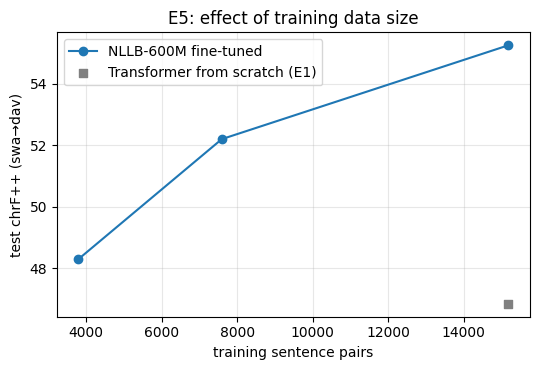

In [ ]:
res = pd.read_csv(f'{RESULTS_DIR}/experiments.csv')
pick = lambda e: res[(res.exp_id == e) & (res.direction == 'swa→dav') & (res.decoding == 'beam4')]['chrF++']
sizes = {'E5_nllb_full_p25': len(subsets['p25']), 'E5_nllb_full_p50': len(subsets['p50']), 'E2_nllb_full': len(train_df)}
pts = [(n, pick(e).iloc[0]) for e, n in sizes.items() if len(pick(e))]
plt.figure(figsize=(5.5, 3.8))
if pts:
    plt.plot(*zip(*pts), 'o-', label='NLLB-600M fine-tuned')
if len(pick('E1_transformer')):
    plt.scatter([len(train_df)], [pick('E1_transformer').iloc[0]], marker='s', color='gray', label='Transformer from scratch (E1)')
if len(pick('E0a_copy')):
    plt.axhline(pick('E0a_copy').iloc[0], ls=':', color='gray', label='copy baseline (E0a)')
plt.xlabel('training sentence pairs'); plt.ylabel('test chrF++ (swa→dav)'); plt.title('E5: effect of training data size')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/e5_learning_curve.png', dpi=150); plt.show()

## E4 · LoRA (parameter-efficient fine-tuning), swa→dav

LoRA (Hu et al., 2022) freezes the 615M pretrained weights and learns small low-rank updates *W + BA* (rank 16) inside the attention and feed-forward layers. Note: the embeddings, including our new `dav_Latn` tag, stay frozen at their Kamba initialisation — a limitation worth discussing if LoRA under-performs.

In [ ]:
!pip install -q "torchao>=0.16.0"

m, h = run_experiment('E4_nllb_lora', [('swa', 'dav')], train_df, method='lora', max_epochs=6,
                      save_dir=f'{MODELS_DIR}/e4_lora_adapter')
free(m)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

E4_nllb_lora: lora | trainable 8.7M / 624M (1.39%)
15184 training pairs, 949 batches/epoch, directions [('swa', 'dav')]


[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

ep 1 | train loss 5.054 | val chrF++ {'swa→dav': 34.91} | 4.3 min                    


[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

...

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

ep 6 | train loss 2.868 | val chrF++ {'swa→dav': 52.0} | 3.8 min                    


[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

[E4_nllb_lora] swa→dav  beam4  BLEU= 22.90  chrF++= 53.22  15184 train pairs; best epoch 6/6; trainable 8.7M; 23 min. 


Saved to /content/drive/MyDrive/kidawida-mt/models/e4_lora_adapter


## Results table and validation curves

In [ ]:
res = pd.read_csv(f'{RESULTS_DIR}/experiments.csv')
main = res[res.decoding.isin(['beam4', '-'])]
table = main.pivot_table(index=['exp_id', 'model'], columns='direction', values=['chrF++', 'BLEU'], aggfunc='first')
table.to_csv(f'{RESULTS_DIR}/results_table.csv')
table

BLEU          \
direction                                                 dav→swa swa→dav   
exp_id                    model                                             
E0a_copy                  copy source                        1.73    1.73   
E0b_nllb_zeroshot_kam-swh NLLB-200-600M (no training)        1.97     NaN   
E0b_nllb_zeroshot_swh-kam NLLB-200-600M (no training)         NaN    0.18   
E0b_nllb_zeroshot_swh-kik NLLB-200-600M (no training)         NaN    0.21   
E0b_nllb_zeroshot_swh-swh NLLB-200-600M (no training)        2.81     NaN   
E1_transformer            Transformer from scratch (7.5M)   22.08   18.07   
E2_nllb_full              NLLB-600M full FT                   NaN   24.18   
E3_nllb_full              NLLB-600M full FT                 32.52     NaN   
E4_nllb_lora              NLLB-600M LoRA r=16                 NaN   22.90   
E5_nllb_full_p25          NLLB-600M full FT                   NaN   17.94   
E5_nllb_full_p50          NLLB-600M full FT                   NaN   21.47   
E6_nllb_bidirectional     NLLB-600M full FT                 31.97   24.08   

                                                           chrF++          
direction                                                 dav→swa swa→dav  
exp_id                    model                                            
E0a_copy                  copy source                       19.26   18.95  
E0b_nllb_zeroshot_kam-swh NLLB-200-600M (no training)       17.71     NaN  
E0b_nllb_zeroshot_swh-kam NLLB-200-600M (no training)         NaN   10.64  
E0b_nllb_zeroshot_swh-kik NLLB-200-600M (no training)         NaN   10.72  
E0b_nllb_zeroshot_swh-swh NLLB-200-600M (no training)       20.67     NaN  
E1_transformer            Transformer from scratch (7.5M)   49.06   46.85  
E2_nllb_full              NLLB-600M full FT                   NaN   55.25  
E3_nllb_full              NLLB-600M full FT                 58.08     NaN  
E4_nllb_lora              NLLB-600M LoRA r=16                 NaN   53.22  
E5_nllb_full_p25          NLLB-600M full FT                   NaN   48.30  
E5_nllb_full_p50          NLLB-600M full FT                   NaN   52.20  
E6_nllb_bidirectional     NLLB-600M full FT                 57.17   54.39

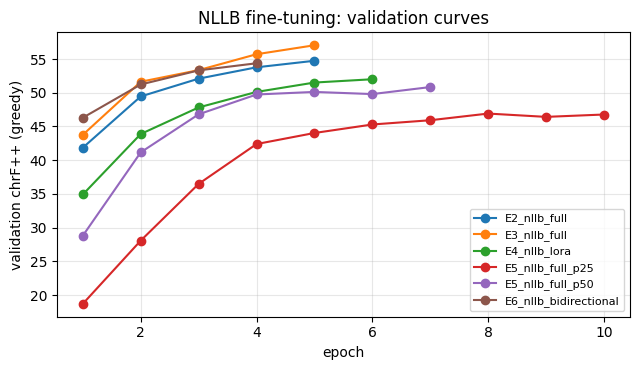

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for f in sorted(os.listdir(CURVE_DIR)):
    h = pd.read_csv(f'{CURVE_DIR}/{f}')
    ax.plot(h.epoch, h['val_chrF++'], 'o-', label=f.replace('.csv', ''))
ax.set_xlabel('epoch'); ax.set_ylabel('validation chrF++ (greedy)'); ax.set_title('NLLB fine-tuning: validation curves')
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/nllb_val_curves.png', dpi=150); plt.show()